## Import dependencies

In [10]:
import pandas as pd
import mlflow.sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
)
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from src.studentrisk_ai.data_utils import process_data

# Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


## MLflow setup

In [11]:
from pathlib import Path

tracking_db = Path("../../mlflow.db").resolve()
mlflow.set_tracking_uri(f"sqlite:///{tracking_db}")
mlflow.set_experiment("Student Mental Health Risk Prediction")

X_train, y_train, X_test, y_test = process_data(
    "../../data/raw/student_mental_health.csv"
)

print(X_train.shape, X_test.shape)
target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

(1600, 18) (400, 18)


## Train and compare models

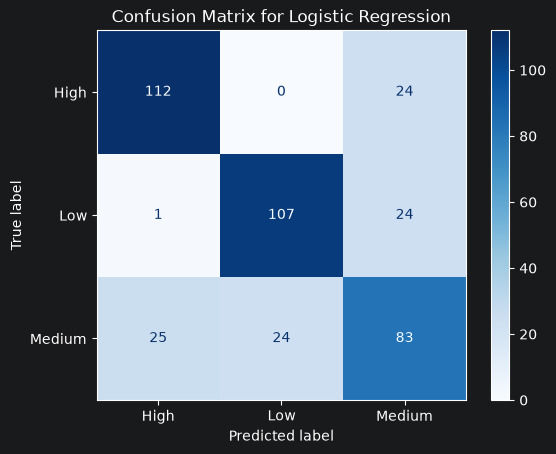

2026/11/11 15:22:48 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


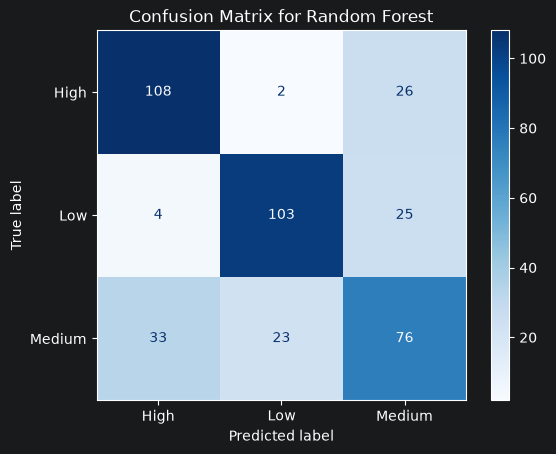

2026/11/11 15:23:03 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


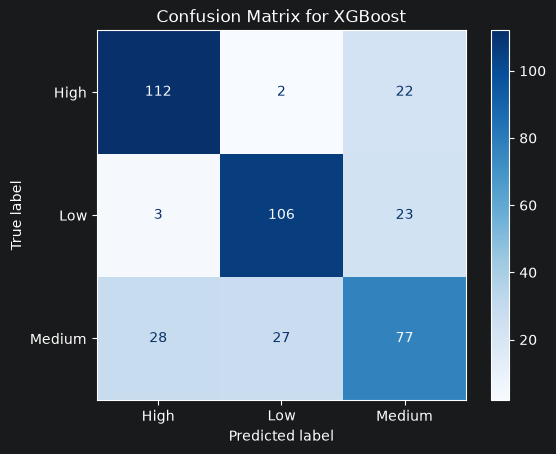

2026/11/11 15:23:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


,accuracy,precision,recall,f1_score,cv_best_f1_weighted
model,,,,,
Logistic Regression,0.755,0.755,0.755,0.755,0.749
Random Forest,0.718,0.716,0.718,0.716,0.674
XGBoost,0.738,0.734,0.738,0.735,0.696


In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss",
    ),
}

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 10.0],
        "model__solver": ["lbfgs"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 4],
        "model__learning_rate": [0.05, 0.1],
    },
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
predictions = {}
probabilities = {}
run_ids = {}

if mlflow.active_run() is not None:
    mlflow.end_run()

for model_name, model in models.items():
    model_pipeline = Pipeline([
        ("model", model),
    ])
    with mlflow.start_run(run_name=model_name):
        run_ids[model_name] = mlflow.active_run().info.run_id
        grid_search = GridSearchCV(
            estimator=model_pipeline,
            param_grid=param_grids[model_name],
            scoring="f1_weighted",
            cv=cv,
            n_jobs=-1,
            refit=True,
        )
        grid_search.fit(X_train, y_train_encoded)
        model_pipeline = grid_search.best_estimator_
        y_pred_encoded = model_pipeline.predict(X_test)
        y_proba = model_pipeline.predict_proba(X_test)
        y_pred = target_encoder.inverse_transform(y_pred_encoded.astype(int))
        predictions[model_name] = y_pred
        probabilities[model_name] = y_proba

        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=target_encoder.classes_,
        )
        disp.plot(cmap="Blues", values_format="d")
        plt.title(f"Confusion Matrix for {model_name}")
        file_name = f"confusion_matrix_{model_name.replace(' ', '_')}.png"
        plt.savefig(file_name, bbox_inches="tight")
        mlflow.log_artifact(file_name)
        plt.show()
        plt.close(disp.figure_)

        metrics = {
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
            "recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
            "f1_score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        }
        mlflow.log_params(model_pipeline.get_params())
        mlflow.log_params(
            {f"best_{key}": value for key, value in grid_search.best_params_.items()}
        )
        mlflow.log_metric("cv_best_f1_weighted", grid_search.best_score_)
        cv_results_file = f"cv_results_{model_name.replace(' ', '_')}.csv"
        pd.DataFrame(grid_search.cv_results_).to_csv(cv_results_file, index=False)
        mlflow.log_artifact(cv_results_file, artifact_path="cross_validation")
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(
            model_pipeline,
            name="model",
            skops_trusted_types=[
                "sklearn.tree._tree.Tree",
                "xgboost.core.Booster",
                "xgboost.sklearn.XGBClassifier",
            ],
        )

        results.append(
            {
                "model": model_name,
                **metrics,
                "cv_best_f1_weighted": grid_search.best_score_,
            }
        )

results_df = pd.DataFrame(results).set_index("model").round(3)
display(results_df)


## Reports and confusion matrices


Logistic Regression


,precision,recall,f1-score,support
High,0.812,0.824,0.818,136.000
Low,0.817,0.811,0.814,132.000
Medium,0.634,0.629,0.631,132.000
accuracy,0.755,0.755,0.755,0.755
macro avg,0.754,0.754,0.754,400.000
weighted avg,0.755,0.755,0.755,400.000


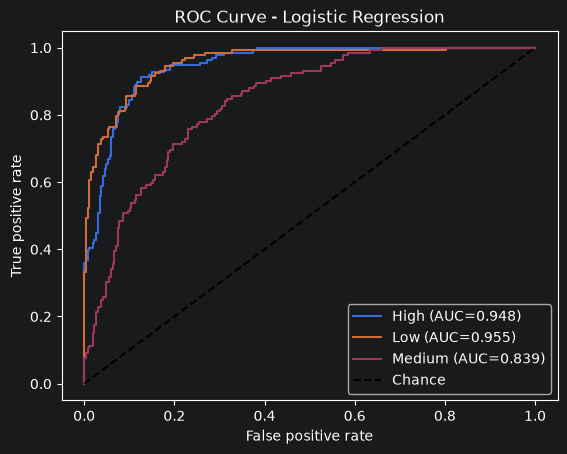

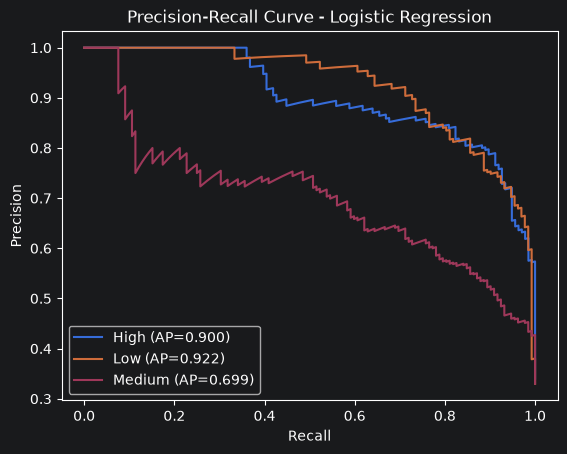


Random Forest


,precision,recall,f1-score,support
High,0.745,0.794,0.769,136.000
Low,0.805,0.780,0.792,132.000
Medium,0.598,0.576,0.587,132.000
accuracy,0.718,0.718,0.718,0.718
macro avg,0.716,0.717,0.716,400.000
weighted avg,0.716,0.718,0.716,400.000


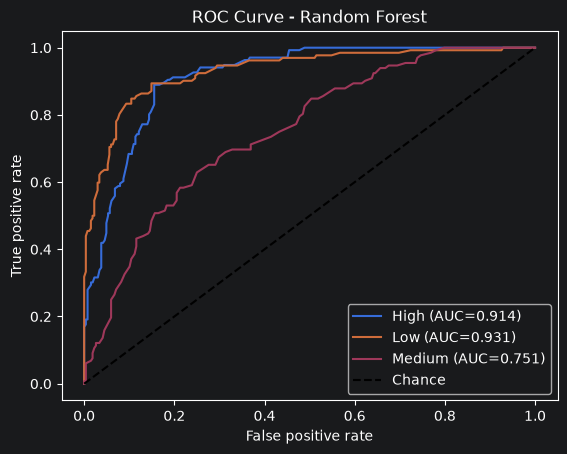

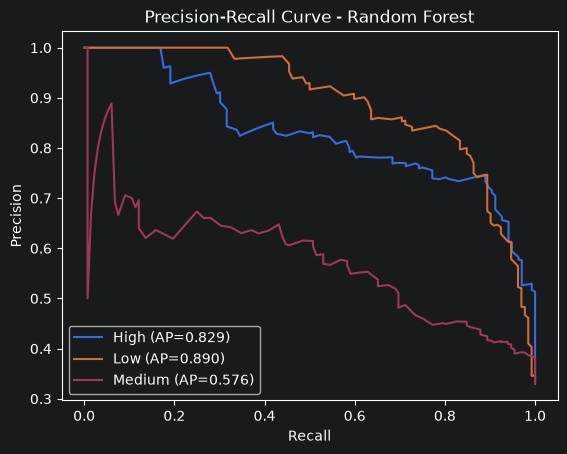


XGBoost


,precision,recall,f1-score,support
High,0.783,0.824,0.803,136.000
Low,0.785,0.803,0.794,132.000
Medium,0.631,0.583,0.606,132.000
accuracy,0.738,0.738,0.738,0.738
macro avg,0.733,0.737,0.734,400.000
weighted avg,0.734,0.738,0.735,400.000


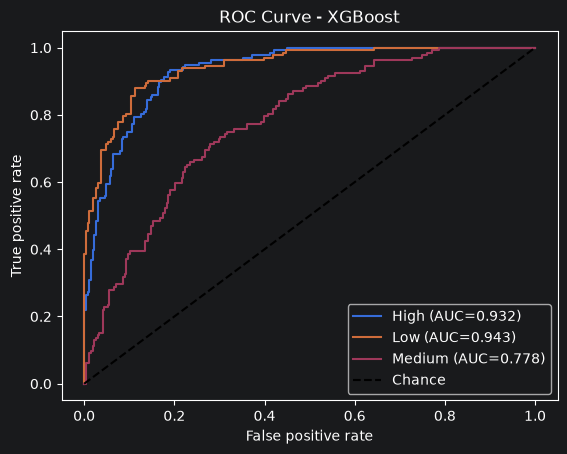

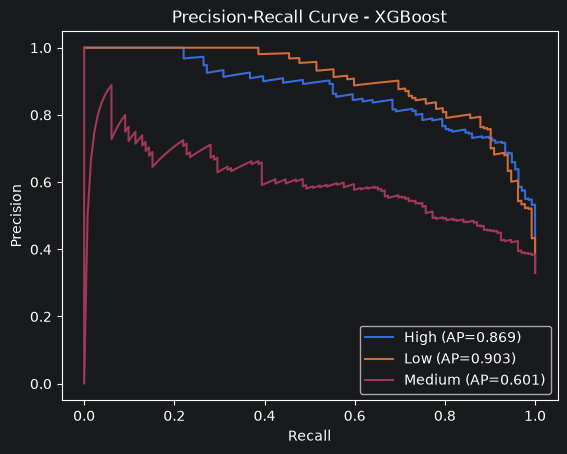

In [13]:
y_test_binary = label_binarize(y_test_encoded, classes=range(len(target_encoder.classes_)))

for model_name, y_pred in predictions.items():
    report = pd.DataFrame(
        classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    ).transpose().round(3)
    print(f"\n{model_name}")
    display(report)

    safe_name = model_name.replace(" ", "_")
    report_file = f"classification_report_{safe_name}.csv"
    report.to_csv(report_file)

    fig, ax = plt.subplots()
    for class_index, class_name in enumerate(target_encoder.classes_):
        fpr, tpr, _ = roc_curve(y_test_binary[:, class_index], probabilities[model_name][:, class_index])
        ax.plot(fpr, tpr, label=f"{class_name} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set(title=f"ROC Curve - {model_name}", xlabel="False positive rate", ylabel="True positive rate")
    ax.legend()
    roc_file = f"roc_curve_{safe_name}.png"
    fig.savefig(roc_file, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots()
    for class_index, class_name in enumerate(target_encoder.classes_):
        precision, recall, _ = precision_recall_curve(
            y_test_binary[:, class_index], probabilities[model_name][:, class_index]
        )
        ap = average_precision_score(
            y_test_binary[:, class_index], probabilities[model_name][:, class_index]
        )
        ax.plot(recall, precision, label=f"{class_name} (AP={ap:.3f})")
    ax.set(title=f"Precision-Recall Curve - {model_name}", xlabel="Recall", ylabel="Precision")
    ax.legend()
    pr_file = f"precision_recall_curve_{safe_name}.png"
    fig.savefig(pr_file, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    with mlflow.start_run(run_id=run_ids[model_name]):
        for artifact_file in (report_file, roc_file, pr_file):
            mlflow.log_artifact(artifact_file, artifact_path="evaluation")